In [1]:
import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
OCT_DIR = Path("../OCT")

print(OCT_DIR.resolve())
print(OCT_DIR.exists())
print(list(OCT_DIR.iterdir()))

C:\Users\spgai\OneDrive\Documents\NetraDrishti\OCT
True
[WindowsPath('../OCT/test'), WindowsPath('../OCT/train')]


In [3]:
TRAIN_DIR = OCT_DIR / "train"
TEST_DIR = OCT_DIR / "test"

for split, split_dir in [("Train", TRAIN_DIR), ("Test", TEST_DIR)]:
    print(f"\n{split} set")
    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob("*")))
            print(f"{class_dir.name}: {count}")


Train set
CNV: 37205
DME: 11348
DRUSEN: 8616
NORMAL: 51140

Test set
CNV: 250
DME: 250
DRUSEN: 250
NORMAL: 250


In [4]:
from collections import Counter
from PIL import Image

def sample_image_sizes(split_dir, samples_per_class=100):
    sizes = Counter()

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        files = list(class_dir.glob("*"))[:samples_per_class]

        for file in files:
            try:
                with Image.open(file) as img:
                    sizes[img.size] += 1
            except Exception:
                pass

    return sizes

train_sizes = sample_image_sizes(TRAIN_DIR)

print("Image sizes found in sample:")
for size, count in train_sizes.most_common():
    print(size, ":", count)

Image sizes found in sample:
(512, 496) : 203
(768, 496) : 88
(512, 512) : 63
(1536, 496) : 46


In [5]:
def inspect_image_geometry(split_dir, samples_per_class=100):
    records = []

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        files = list(class_dir.glob("*"))[:samples_per_class]

        for file in files:
            try:
                with Image.open(file) as img:
                    width, height = img.size

                records.append({
                    "class": class_dir.name,
                    "width": width,
                    "height": height,
                    "aspect_ratio": width / height
                })

            except Exception:
                pass

    return pd.DataFrame(records)


geometry_df = inspect_image_geometry(TRAIN_DIR)

geometry_df.describe()

,width,height,aspect_ratio
count,400.000000,400.000000,400.000000
mean,686.080000,498.520000,1.378145
std,323.979506,5.835644,0.656021
min,512.000000,496.000000,1.000000
25%,512.000000,496.000000,1.032258
50%,512.000000,496.000000,1.032258
75%,768.000000,496.000000,1.548387
max,1536.000000,512.000000,3.096774


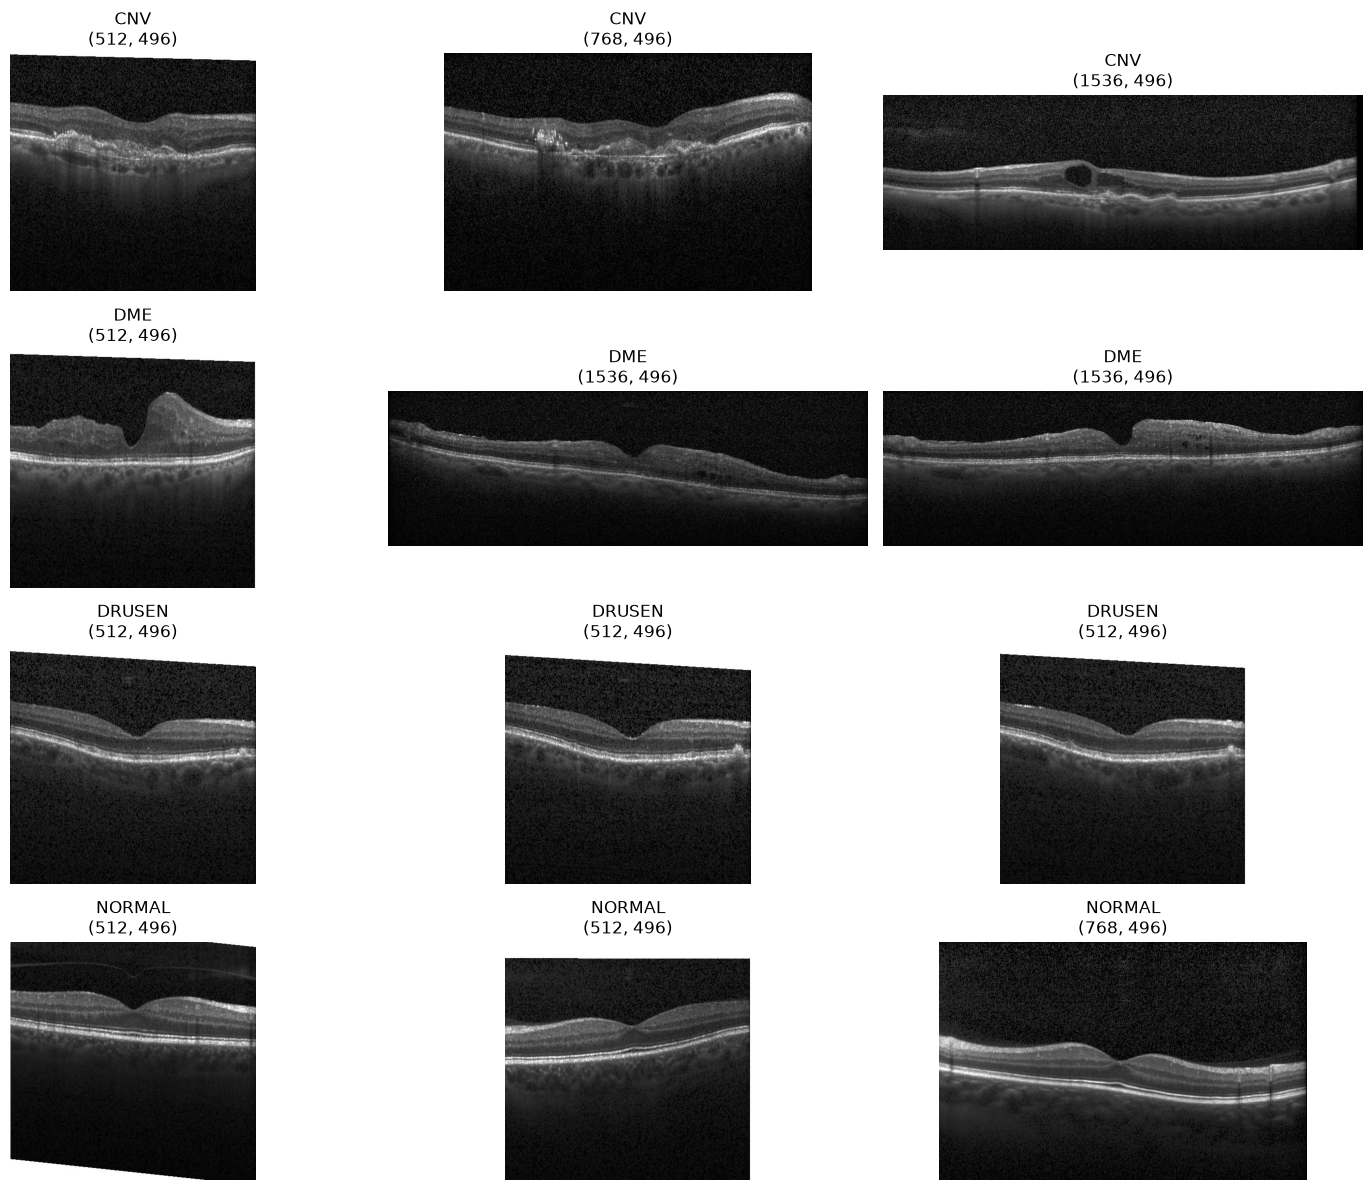

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))

classes = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir()])

for row, class_name in enumerate(classes):
    class_dir = TRAIN_DIR / class_name
    image_files = list(class_dir.glob("*"))[:3]

    for col, image_file in enumerate(image_files):
        img = Image.open(image_file)

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(
            f"{class_name}\n{img.size}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [7]:
dimension_by_class = (
    geometry_df
    .groupby(["class", "width", "height"])
    .size()
    .reset_index(name="count")
)

dimension_by_class

,class,width,height,count
0,CNV,512,496,45
1,CNV,768,496,31
2,CNV,1536,496,24
3,DME,512,496,24
4,DME,512,512,63
5,DME,768,496,8
6,DME,1536,496,5
7,DRUSEN,512,496,66
8,DRUSEN,768,496,25
9,DRUSEN,1536,496,9


In [8]:
def collect_image_dimensions(split_dir):
    records = []

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for image_file in class_dir.iterdir():
            if not image_file.is_file():
                continue

            try:
                with Image.open(image_file) as img:
                    width, height = img.size

                records.append({
                    "class": class_dir.name,
                    "width": width,
                    "height": height,
                    "aspect_ratio": width / height
                })

            except Exception as e:
                print(f"Could not read: {image_file}")

    return pd.DataFrame(records)


full_geometry_df = collect_image_dimensions(TRAIN_DIR)

print("Total images inspected:", len(full_geometry_df))

Total images inspected: 108309


In [9]:
full_dimension_counts = (
    full_geometry_df
    .groupby(["class", "width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(["class", "width", "height"])
)

full_dimension_counts

,class,width,height,count
0,CNV,384,496,15
1,CNV,512,496,19912
2,CNV,768,496,12050
3,CNV,1024,496,173
4,CNV,1536,496,5055
5,DME,512,496,1485
6,DME,512,512,8659
7,DME,768,496,816
8,DME,1024,496,14
9,DME,1536,496,374


In [10]:
test_geometry_df = collect_image_dimensions(TEST_DIR)

print("Total test images inspected:", len(test_geometry_df))

test_dimension_counts = (
    test_geometry_df
    .groupby(["class", "width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(["class", "width", "height"])
)

test_dimension_counts

Total test images inspected: 1000


,class,width,height,count
0,CNV,768,496,1
1,CNV,1024,496,228
2,CNV,1536,496,21
3,DME,768,496,2
4,DME,1024,496,234
5,DME,1536,496,14
6,DRUSEN,642,277,1
7,DRUSEN,768,496,1
8,DRUSEN,900,455,1
9,DRUSEN,1024,496,239


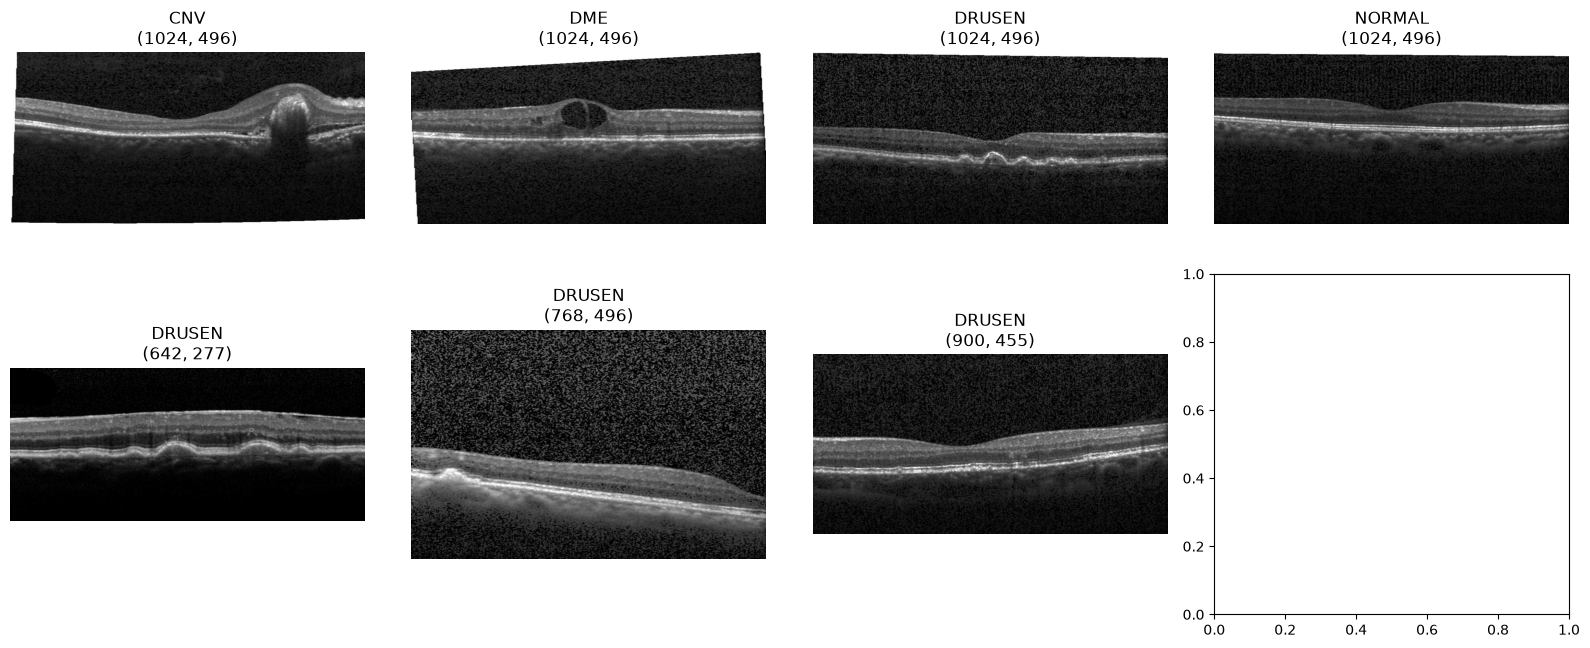

In [11]:
# Show a few representative test images, including unusual dimensions

selected_images = []

for class_dir in sorted(TEST_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    # Take the first image from each class
    image_files = list(class_dir.glob("*"))
    if image_files:
        selected_images.append(image_files[0])

# Add the unusual DRUSEN images we found
drusen_dir = TEST_DIR / "DRUSEN"

for image_file in drusen_dir.glob("*"):
    with Image.open(image_file) as img:
        if img.size in [(642, 277), (900, 455), (768, 496)]:
            selected_images.append(image_file)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()

for ax, image_file in zip(axes, selected_images):
    img = Image.open(image_file)

    ax.imshow(img, cmap="gray")
    ax.set_title(f"{image_file.parent.name}\n{img.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Inspect filenames from each class
for class_name in classes:
    class_dir = TRAIN_DIR / class_name
    files = list(class_dir.glob("*"))[:10]

    print(f"\n{class_name}")
    for file in files:
        print(file.name)


CNV
CNV-1016042-1.jpeg
CNV-1016042-10.jpeg
CNV-1016042-100.jpeg
CNV-1016042-101.jpeg
CNV-1016042-102.jpeg
CNV-1016042-103.jpeg
CNV-1016042-104.jpeg
CNV-1016042-105.jpeg
CNV-1016042-106.jpeg
CNV-1016042-107.jpeg

DME
DME-1072015-1.jpeg
DME-1072015-2.jpeg
DME-1072015-3.jpeg
DME-1072015-4.jpeg
DME-1072015-5.jpeg
DME-1072015-6.jpeg
DME-1072015-7.jpeg
DME-1083927-1.jpeg
DME-1083927-10.jpeg
DME-1083927-11.jpeg

DRUSEN
DRUSEN-1001666-1.jpeg
DRUSEN-1001666-2.jpeg
DRUSEN-1001666-3.jpeg
DRUSEN-1001666-4.jpeg
DRUSEN-1001666-5.jpeg
DRUSEN-1001666-6.jpeg
DRUSEN-1001666-7.jpeg
DRUSEN-1001666-8.jpeg
DRUSEN-1001666-9.jpeg
DRUSEN-1001772-1.jpeg

NORMAL
NORMAL-1001772-1.jpeg
NORMAL-1001772-10.jpeg
NORMAL-1001772-11.jpeg
NORMAL-1001772-12.jpeg
NORMAL-1001772-13.jpeg
NORMAL-1001772-14.jpeg
NORMAL-1001772-2.jpeg
NORMAL-1001772-3.jpeg
NORMAL-1001772-4.jpeg
NORMAL-1001772-5.jpeg


In [13]:
from collections import Counter

for class_name in classes:
    class_dir = TRAIN_DIR / class_name

    group_ids = []

    for file in class_dir.glob("*.jpeg"):
        parts = file.stem.split("-")

        # Expected pattern: CLASS-GROUPID-IMAGE_NUMBER
        if len(parts) >= 3:
            group_ids.append(parts[1])

    counts = Counter(group_ids)

    print(f"\n{class_name}")
    print("Unique group IDs:", len(counts))
    print("Images:", sum(counts.values()))
    print("Largest groups:", counts.most_common(5))


CNV
Unique group IDs: 791
Images: 37205
Largest groups: [('1188386', 813), ('6652117', 613), ('6666538', 585), ('7907754', 469), ('172472', 459)]

DME
Unique group IDs: 709
Images: 11348
Largest groups: [('3064922', 252), ('4242335', 251), ('30521', 231), ('8525575', 202), ('8602716', 156)]

DRUSEN
Unique group IDs: 713
Images: 8616
Largest groups: [('8086850', 260), ('8023853', 163), ('8986660', 155), ('364469', 142), ('1997439', 136)]

NORMAL
Unique group IDs: 3434
Images: 51140
Largest groups: [('4345468', 65), ('5500082', 65), ('5942608', 65), ('1888479', 64), ('5689330', 64)]


In [14]:
# Check whether the same numeric ID appears in multiple classes

group_to_classes = {}

for class_name in classes:
    class_dir = TRAIN_DIR / class_name

    for file in class_dir.glob("*.jpeg"):
        parts = file.stem.split("-")

        if len(parts) >= 3:
            group_id = parts[1]

            group_to_classes.setdefault(group_id, set()).add(class_name)

cross_class_groups = {
    group_id: class_set
    for group_id, class_set in group_to_classes.items()
    if len(class_set) > 1
}

print("Groups appearing in multiple classes:", len(cross_class_groups))

for group_id, class_set in list(cross_class_groups.items())[:20]:
    print(group_id, sorted(class_set))

Groups appearing in multiple classes: 741
1016042 ['CNV', 'DRUSEN', 'NORMAL']
1077513 ['CNV', 'DRUSEN', 'NORMAL']
1083927 ['CNV', 'DME']
1112835 ['CNV', 'DRUSEN']
1117376 ['CNV', 'DRUSEN', 'NORMAL']
1130960 ['CNV', 'DRUSEN']
1131664 ['CNV', 'DRUSEN']
1136126 ['CNV', 'DRUSEN']
1147102 ['CNV', 'DRUSEN', 'NORMAL']
1169820 ['CNV', 'DME', 'DRUSEN']
1173253 ['CNV', 'DRUSEN']
1177084 ['CNV', 'NORMAL']
1183510 ['CNV', 'DRUSEN']
1290410 ['CNV', 'DRUSEN']
1305450 ['CNV', 'DRUSEN']
1356232 ['CNV', 'DME', 'DRUSEN']
1455244 ['CNV', 'DRUSEN']
1605492 ['CNV', 'NORMAL']
163081 ['CNV', 'DRUSEN']
1641792 ['CNV', 'DME', 'DRUSEN']


In [15]:
# Check whether any group IDs occur in both TRAIN and TEST

def get_group_ids(split_dir):
    group_ids = set()

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        for file in class_dir.glob("*.jpeg"):
            parts = file.stem.split("-")

            if len(parts) >= 3:
                group_ids.add(parts[1])

    return group_ids


train_group_ids = get_group_ids(TRAIN_DIR)
test_group_ids = get_group_ids(TEST_DIR)

overlap = train_group_ids & test_group_ids

print("Unique train groups:", len(train_group_ids))
print("Unique test groups:", len(test_group_ids))
print("Groups appearing in BOTH:", len(overlap))

if overlap:
    print("Example overlapping IDs:", list(overlap)[:20])

Unique train groups: 4785
Unique test groups: 635
Groups appearing in BOTH: 0


In [16]:
records = []

for class_name in classes:
    class_dir = TRAIN_DIR / class_name

    for file in class_dir.glob("*.jpeg"):
        parts = file.stem.split("-")

        if len(parts) >= 3:
            group_id = parts[1]

            records.append({
                "path": str(file),
                "class": class_name,
                "group_id": group_id
            })

train_df = pd.DataFrame(records)

print("Total images:", len(train_df))
print("Unique groups:", train_df["group_id"].nunique())

train_df.head()

Total images: 108309
Unique groups: 4785


,path,class,group_id
0,..\OCT\train\CNV\CNV-1016042-1.jpeg,CNV,1016042
1,..\OCT\train\CNV\CNV-1016042-10.jpeg,CNV,1016042
2,..\OCT\train\CNV\CNV-1016042-100.jpeg,CNV,1016042
3,..\OCT\train\CNV\CNV-1016042-101.jpeg,CNV,1016042
4,..\OCT\train\CNV\CNV-1016042-102.jpeg,CNV,1016042


In [17]:
from sklearn.model_selection import StratifiedGroupKFold

X = train_df["path"]
y = train_df["class"]
groups = train_df["group_id"]

sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(sgkf.split(X, y, groups))

train_split = train_df.iloc[train_idx].copy()
val_split = train_df.iloc[val_idx].copy()

print("Training images:", len(train_split))
print("Validation images:", len(val_split))

print("\nTraining class distribution:")
print(train_split["class"].value_counts())

print("\nValidation class distribution:")
print(val_split["class"].value_counts())

print("\nGroup overlap:")
print(len(
    set(train_split["group_id"]) &
    set(val_split["group_id"])
))

Training images: 97477
Validation images: 10832

Training class distribution:
class
NORMAL    46025
CNV       33485
DME       10213
DRUSEN     7754
Name: count, dtype: int64

Validation class distribution:
class
NORMAL    5115
CNV       3720
DME       1135
DRUSEN     862
Name: count, dtype: int64

Group overlap:
0


In [18]:
from PIL import ImageOps

IMG_SIZE = 256

def resize_and_pad(image, size=IMG_SIZE):
    # Preserve aspect ratio while fitting the image inside the target square
    image = image.copy()
    image.thumbnail((size, size), Image.Resampling.LANCZOS)

    # Create a square canvas
    padded = Image.new("L", (size, size), color=0)

    # Center the resized image
    x = (size - image.width) // 2
    y = (size - image.height) // 2

    padded.paste(image, (x, y))

    return padded

In [19]:
# Find one example of each unusual DRUSEN test-image size
target_sizes = [(642, 277), (900, 455), (768, 496)]

unusual_images = []

for image_file in (TEST_DIR / "DRUSEN").glob("*.jpeg"):
    with Image.open(image_file) as img:
        if img.size in target_sizes:
            unusual_images.append(image_file)

print("Found:")
for image_file in unusual_images:
    with Image.open(image_file) as img:
        print(image_file.name, img.size)

Found:
DRUSEN-52917-1.jpeg (642, 277)
DRUSEN-8129501-1.jpeg (768, 496)
DRUSEN-9012418-1.jpeg (900, 455)


FileNotFoundError: [Errno 2] No such file or directory: '..\\OCT\\test\\NORMAL\\NORMAL-1001772-1.jpeg'

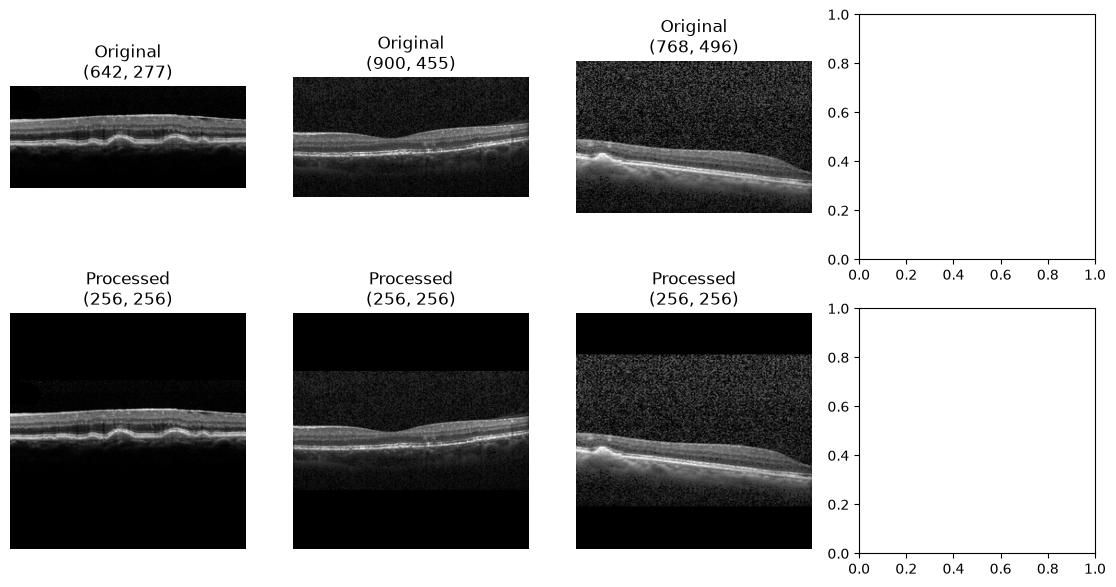

In [20]:
test_images = [
    TEST_DIR / "DRUSEN" / "DRUSEN-52917-1.jpeg",       # 642 × 277
    TEST_DIR / "DRUSEN" / "DRUSEN-9012418-1.jpeg",     # 900 × 455
    TEST_DIR / "DRUSEN" / "DRUSEN-8129501-1.jpeg",     # 768 × 496
    TEST_DIR / "NORMAL" / "NORMAL-1001772-1.jpeg"
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, image_path in enumerate(test_images):
    original = Image.open(image_path).convert("L")
    processed = resize_and_pad(original)

    axes[0, col].imshow(original, cmap="gray")
    axes[0, col].set_title(f"Original\n{original.size}")
    axes[0, col].axis("off")

    axes[1, col].imshow(processed, cmap="gray")
    axes[1, col].set_title(f"Processed\n{processed.size}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

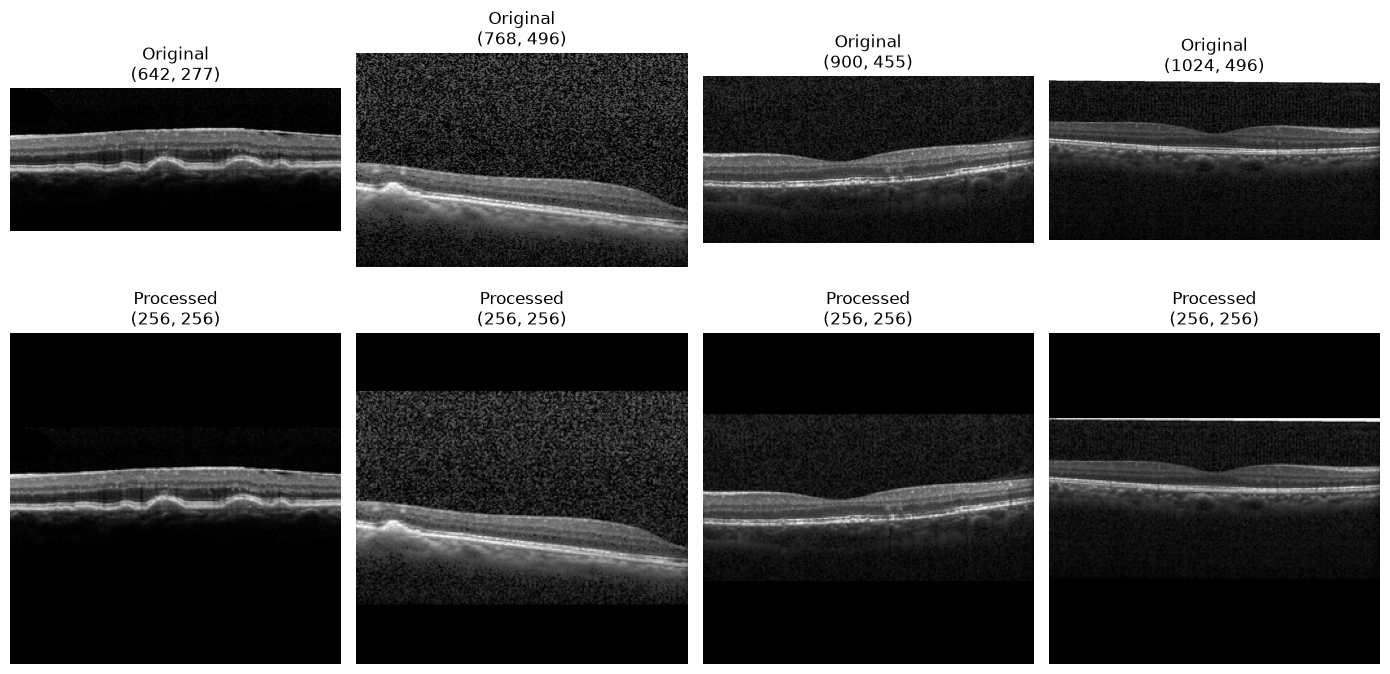

In [21]:
normal_image = next((TEST_DIR / "NORMAL").glob("*.jpeg"))

test_images = unusual_images[:3] + [normal_image]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, image_path in enumerate(test_images):
    original = Image.open(image_path).convert("L")
    processed = resize_and_pad(original)

    axes[0, col].imshow(original, cmap="gray")
    axes[0, col].set_title(f"Original\n{original.size}")
    axes[0, col].axis("off")

    axes[1, col].imshow(processed, cmap="gray")
    axes[1, col].set_title(f"Processed\n{processed.size}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

In [22]:
import torch
from torchvision import transforms

to_tensor = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [23]:
import torch
from torchvision import transforms

IMG_SIZE = 256

# ImageNet normalization for pretrained backbones
imagenet_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

def preprocess_oct(image):
    # Ensure grayscale
    image = image.convert("L")

    # Resize while preserving aspect ratio
    image.thumbnail((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)

    # Convert resized image to tensor: [1, H, W], values 0-1
    tensor = transforms.ToTensor()(image)

    # Normalize the grayscale channel first
    tensor = imagenet_normalize(tensor.repeat(3, 1, 1))

    # Create 256x256 tensor filled with zero-normalized padding
    padded = torch.zeros((3, IMG_SIZE, IMG_SIZE))

    # Center the image
    h, w = tensor.shape[1:]
    y = (IMG_SIZE - h) // 2
    x = (IMG_SIZE - w) // 2

    padded[:, y:y+h, x:x+w] = tensor

    return padded

In [24]:
sample_path = TRAIN_DIR / "CNV" / "CNV-1016042-1.jpeg"

sample_image = Image.open(sample_path)

sample_tensor = preprocess_oct(sample_image)

print("Tensor shape:", sample_tensor.shape)
print("Tensor dtype:", sample_tensor.dtype)
print("Minimum:", sample_tensor.min().item())
print("Maximum:", sample_tensor.max().item())

Tensor shape: torch.Size([3, 256, 256])
Tensor dtype: torch.float32
Minimum: -2.1179039478302
Maximum: 2.640000104904175


In [25]:
class_to_idx = {
    "CNV": 0,
    "DME": 1,
    "DRUSEN": 2,
    "NORMAL": 3
}

idx_to_class = {v: k for k, v in class_to_idx.items()}

print("Class → index:", class_to_idx)
print("Index → class:", idx_to_class)

Class → index: {'CNV': 0, 'DME': 1, 'DRUSEN': 2, 'NORMAL': 3}
Index → class: {0: 'CNV', 1: 'DME', 2: 'DRUSEN', 3: 'NORMAL'}


In [26]:
from torch.utils.data import Dataset
import os

class OCTDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = row["path"]
        class_name = row["class"]

        image = Image.open(image_path)

        image_tensor = preprocess_oct(image)

        label = class_to_idx[class_name]

        return image_tensor, label

In [27]:
train_dataset = OCTDataset(train_split)
val_dataset = OCTDataset(val_split)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 97477
Validation samples: 10832


In [28]:
image_tensor, label = train_dataset[0]

print("Image shape:", image_tensor.shape)
print("Image dtype:", image_tensor.dtype)
print("Label:", label)
print("Class:", idx_to_class[label])

Image shape: torch.Size([3, 256, 256])
Image dtype: torch.float32
Label: 0
Class: CNV


In [29]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 3047
Validation batches: 339


In [30]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])

Images shape: torch.Size([32, 3, 256, 256])
Labels shape: torch.Size([32])
Labels: tensor([3, 3, 0, 1, 0, 2, 3, 3, 3, 3])


In [31]:
import torch
import torch.nn as nn


class OCTCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = OCTCNN(num_classes=4).to(device)

print("Device:", device)
print(model)

Device: cpu
OCTCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(1, 1))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=256, out_features=4, bias=True)
  )
)


In [33]:
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)

Input shape : torch.Size([32, 3, 256, 256])
Output shape: torch.Size([32, 4])


In [34]:
import torch
import numpy as np

class_counts = train_split["class"].value_counts()

class_weights = []

for class_name, class_idx in class_to_idx.items():
    class_weights.append(
        len(train_split) / (len(class_to_idx) * class_counts[class_name])
    )

class_weights = torch.tensor(class_weights, dtype=torch.float32)

print("Class counts:")
print(class_counts)

print("\nClass weights:")
for class_name, weight in zip(class_to_idx.keys(), class_weights):
    print(f"{class_name}: {weight:.4f}")

Class counts:
class
NORMAL    46025
CNV       33485
DME       10213
DRUSEN     7754
Name: count, dtype: int64

Class weights:
CNV: 0.7278
DME: 2.3861
DRUSEN: 3.1428
NORMAL: 0.5295


In [35]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

print(criterion)

CrossEntropyLoss()


In [36]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

In [37]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [38]:
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [39]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: C:\Users\spgai\anaconda3\envs\llava-xpu\python.exe
PyTorch: 2.13.0+xpu
CUDA available: False


In [40]:
print("XPU available:", torch.xpu.is_available())

if torch.xpu.is_available():
    print("XPU device:", torch.xpu.get_device_name(0))

XPU available: True
XPU device: Intel(R) Arc(TM) Graphics


In [41]:
device = torch.device("xpu")

print("Using device:", device)
print("GPU:", torch.xpu.get_device_name(0))

Using device: xpu
GPU: Intel(R) Arc(TM) Graphics


In [42]:
device = torch.device("xpu")

model = OCTCNN(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print("Device:", device)
print("GPU:", torch.xpu.get_device_name(0))

Device: xpu
GPU: Intel(R) Arc(TM) Graphics


In [43]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input device :", images.device)
print("Output device:", outputs.device)
print("Output shape :", outputs.shape)

Input device : xpu:0
Output device: xpu:0
Output shape : torch.Size([32, 4])


In [44]:
EPOCHS = 3

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion,
        device
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/3 | Train Loss: 0.6858 | Train Acc: 0.7521 | Val Loss: 0.3281 | Val Acc: 0.9087
Epoch 2/3 | Train Loss: 0.2974 | Train Acc: 0.9134 | Val Loss: 0.2819 | Val Acc: 0.9201
Epoch 3/3 | Train Loss: 0.2252 | Train Acc: 0.9346 | Val Loss: 0.2250 | Val Acc: 0.9410


In [44]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

In [45]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "CNV",
            "DME",
            "DRUSEN",
            "NORMAL"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

         CNV     0.0000    0.0000    0.0000      3720
         DME     0.0000    0.0000    0.0000      1135
      DRUSEN     0.0000    0.0000    0.0000       862
      NORMAL     0.4722    1.0000    0.6415      5115

    accuracy                         0.4722     10832
   macro avg     0.1181    0.2500    0.1604     10832
weighted avg     0.2230    0.4722    0.3029     10832



C:\Users\spgai\anaconda3\envs\llava-xpu\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\spgai\anaconda3\envs\llava-xpu\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\spgai\anaconda3\envs\llava-xpu\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

In [46]:
cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[   0    0    0 3720]
 [   0    0    0 1135]
 [   0    0    0  862]
 [   0    0    0 5115]]


In [47]:
error_df = val_split.copy().reset_index(drop=True)

error_df["true_idx"] = all_labels
error_df["pred_idx"] = all_predictions

error_df["true_class"] = error_df["true_idx"].map(idx_to_class)
error_df["pred_class"] = error_df["pred_idx"].map(idx_to_class)

errors = error_df[
    error_df["true_class"] != error_df["pred_class"]
].copy()

print("Total validation errors:", len(errors))

Total validation errors: 5717


In [48]:
error_pairs = (
    errors
    .groupby(["true_class", "pred_class"])
    .size()
    .sort_values(ascending=False)
)

print(error_pairs)

true_class  pred_class
CNV         NORMAL        3720
DME         NORMAL        1135
DRUSEN      NORMAL         862
dtype: int64


In [49]:
import matplotlib.pyplot as plt
from PIL import Image

def show_errors(df, true_class, pred_class, n=10):
    subset = df[
        (df["true_class"] == true_class) &
        (df["pred_class"] == pred_class)
    ].head(n)

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, subset.iterrows()):
        image = Image.open(row["path"])

        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"True: {row['true_class']}\n"
            f"Pred: {row['pred_class']}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

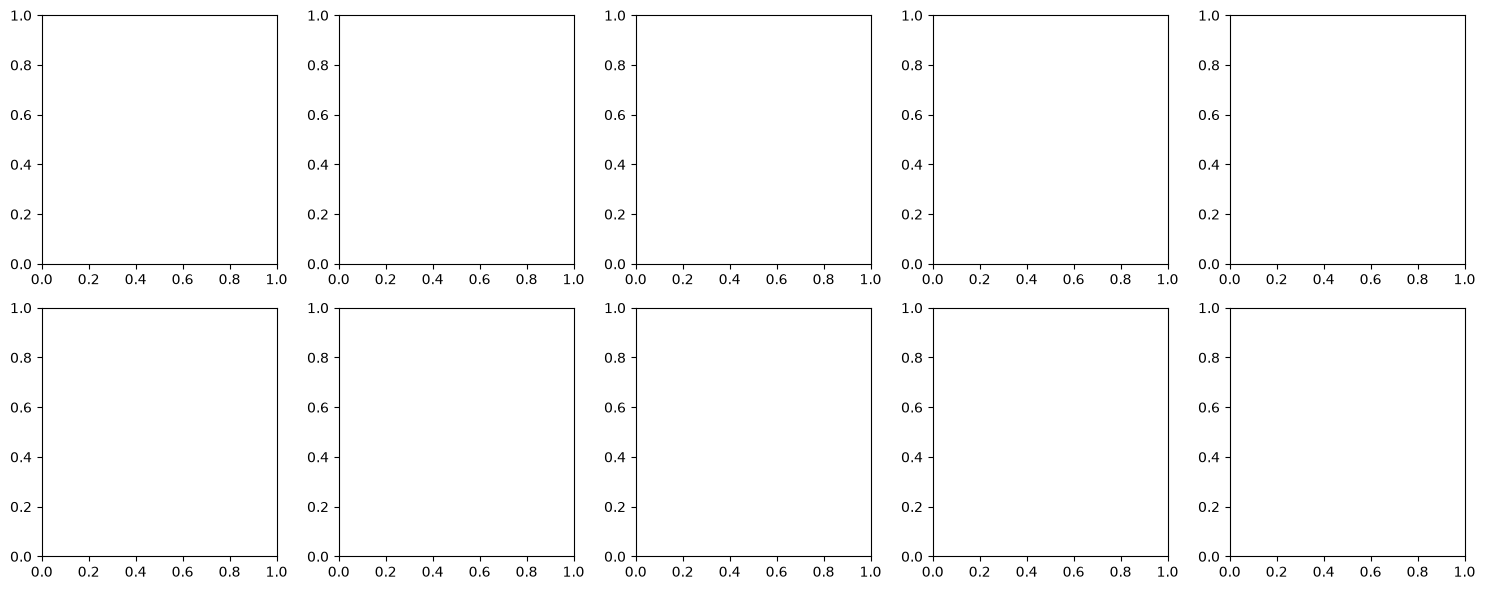

In [50]:
show_errors(errors, "NORMAL", "DRUSEN")

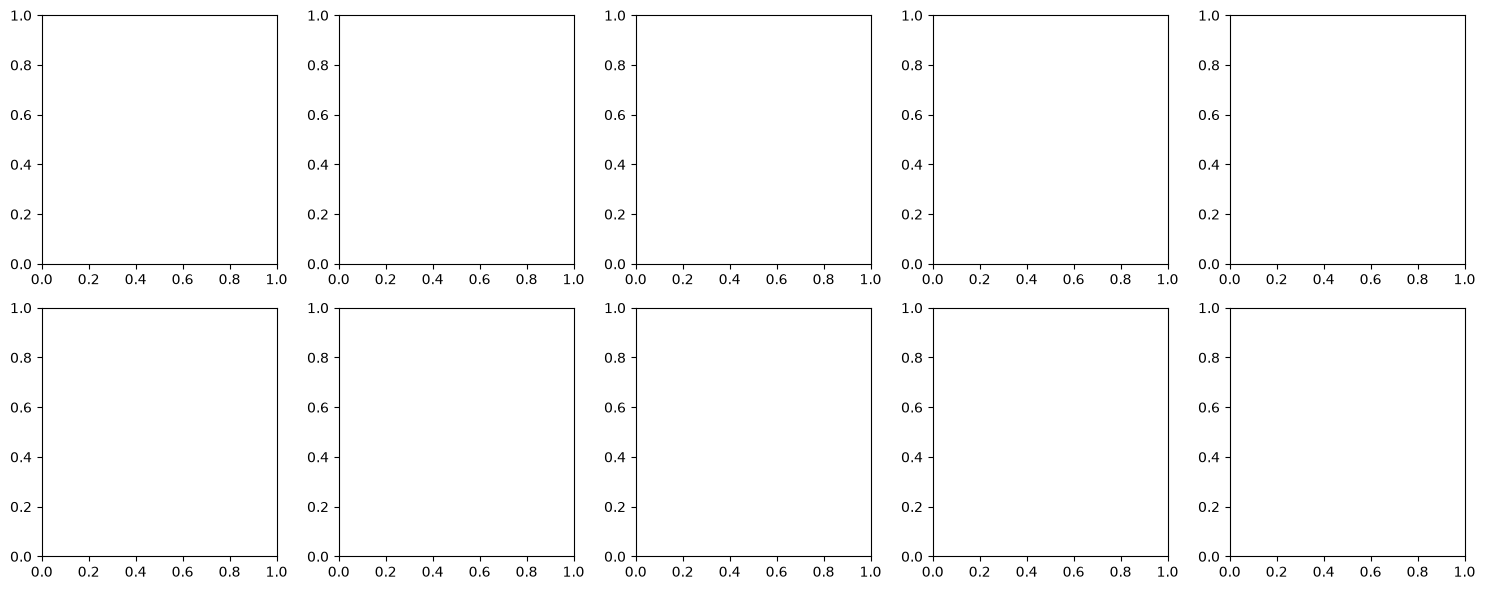

In [51]:
show_errors(errors, "CNV", "DRUSEN")

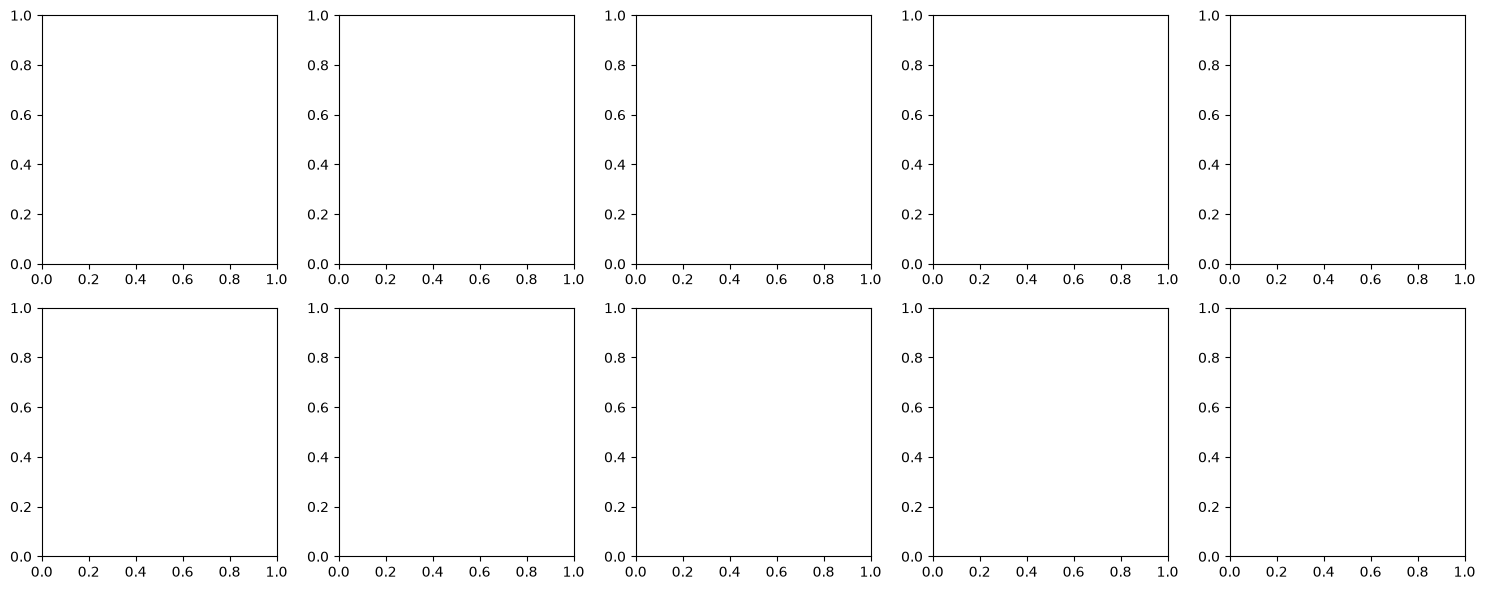

In [52]:
show_errors(errors, "DRUSEN", "CNV")

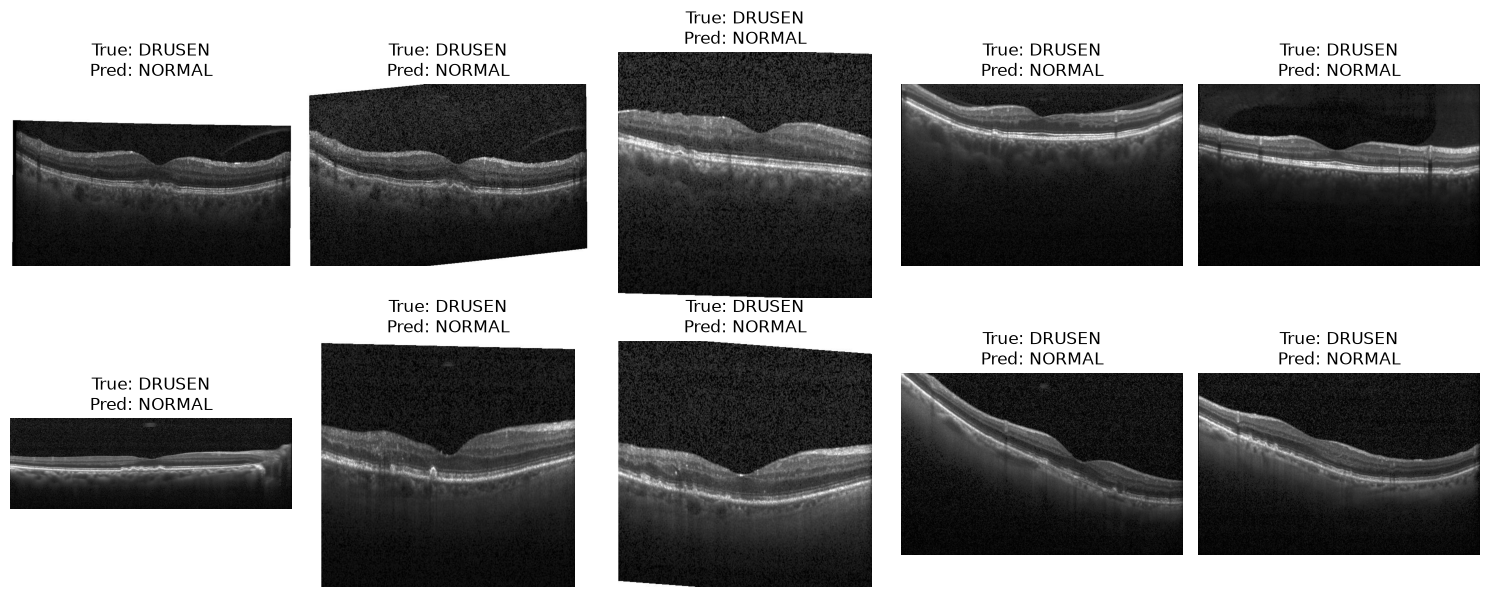

In [53]:
show_errors(errors,"DRUSEN","NORMAL")

In [54]:
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

In [55]:
checkpoint_path = MODEL_DIR / "oct_cnn_baseline_epoch3.pth"

torch.save({
    "epoch": 3,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "class_to_idx": class_to_idx,
    "val_accuracy": 0.9410,
    "val_loss": 0.2250,
}, checkpoint_path)

print(f"Checkpoint saved to: {checkpoint_path}")

Checkpoint saved to: ..\models\oct_cnn_baseline_epoch3.pth


In [56]:
print(checkpoint_path.exists())
print(f"Size: {checkpoint_path.stat().st_size / (1024**2):.2f} MB")

True
Size: 1.49 MB


In [57]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

from torchvision.models import swin_t, Swin_T_Weights

print("Swin Transformer is available.")

PyTorch: 2.13.0+xpu
Torchvision: 0.28.0+xpu
Swin Transformer is available.


In [58]:
import torch
import torch.nn as nn
from torchvision.models import swin_t, Swin_T_Weights

# Load pretrained Swin-Tiny
weights = Swin_T_Weights.DEFAULT
swin_model = swin_t(weights=weights)

# Replace ImageNet classifier with our 4-class classifier
num_features = swin_model.head.in_features

swin_model.head = nn.Linear(
    num_features,
    4
)

# Move to Intel XPU
swin_model = swin_model.to(device)

print(swin_model.head)

Linear(in_features=768, out_features=4, bias=True)


In [59]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = swin_model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Device      :", outputs.device)

Input shape : torch.Size([32, 3, 256, 256])
Output shape: torch.Size([32, 4])
Device      : xpu:0


In [60]:
criterion_swin = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer_swin = torch.optim.AdamW(
    swin_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Swin loss and optimizer ready.")

Swin loss and optimizer ready.


In [61]:
# Save portable train/validation manifests for Kaggle

from pathlib import Path

OCT_ROOT = Path("../OCT").resolve()

def make_portable(df):
    out = df[["path", "class", "group_id"]].copy()
    out["relative_path"] = out["path"].apply(
        lambda p: str(Path(p).resolve().relative_to(OCT_ROOT))
    )
    return out[["relative_path", "class", "group_id"]]

train_manifest = make_portable(train_split)
val_manifest = make_portable(val_split)

train_manifest.to_csv("../models/train_manifest.csv", index=False)
val_manifest.to_csv("../models/val_manifest.csv", index=False)

print(f"Train manifest: {len(train_manifest)} rows")
print(f"Validation manifest: {len(val_manifest)} rows")
print("\nExample:")
print(train_manifest.head())

Train manifest: 97477 rows
Validation manifest: 10832 rows

Example:
                    relative_path class group_id
0    train\CNV\CNV-1016042-1.jpeg   CNV  1016042
1   train\CNV\CNV-1016042-10.jpeg   CNV  1016042
2  train\CNV\CNV-1016042-100.jpeg   CNV  1016042
3  train\CNV\CNV-1016042-101.jpeg   CNV  1016042
4  train\CNV\CNV-1016042-102.jpeg   CNV  1016042


In [ ]:
import time

start_time = time.time()

train_loss, train_acc = train_one_epoch(
    swin_model,
    train_loader,
    criterion_swin,
    optimizer_swin,
    device
)

val_loss, val_acc = validate(
    swin_model,
    val_loader,
    criterion_swin,
    device
)

elapsed_time = time.time() - start_time

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Acc : {train_acc:.4f}")
print(f"Val Loss  : {val_loss:.4f}")
print(f"Val Acc   : {val_acc:.4f}")
print(f"Time      : {elapsed_time / 60:.2f} minutes")